# 00 · Exploração do Fashion-MNIST

Objetivo: conhecer os dados antes de treinar qualquer modelo. Ao fim, responda as perguntas da última célula com suas palavras.

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np

from src.data import CLASS_NAMES, load_fashion_mnist

ds = load_fashion_mnist()
print("treino:", ds.X_train.shape, "| validação:", ds.X_val.shape, "| teste:", ds.X_test.shape)

treino: (50000, 784) | validação: (10000, 784) | teste: (10000, 784)


## 1. Como são as imagens?

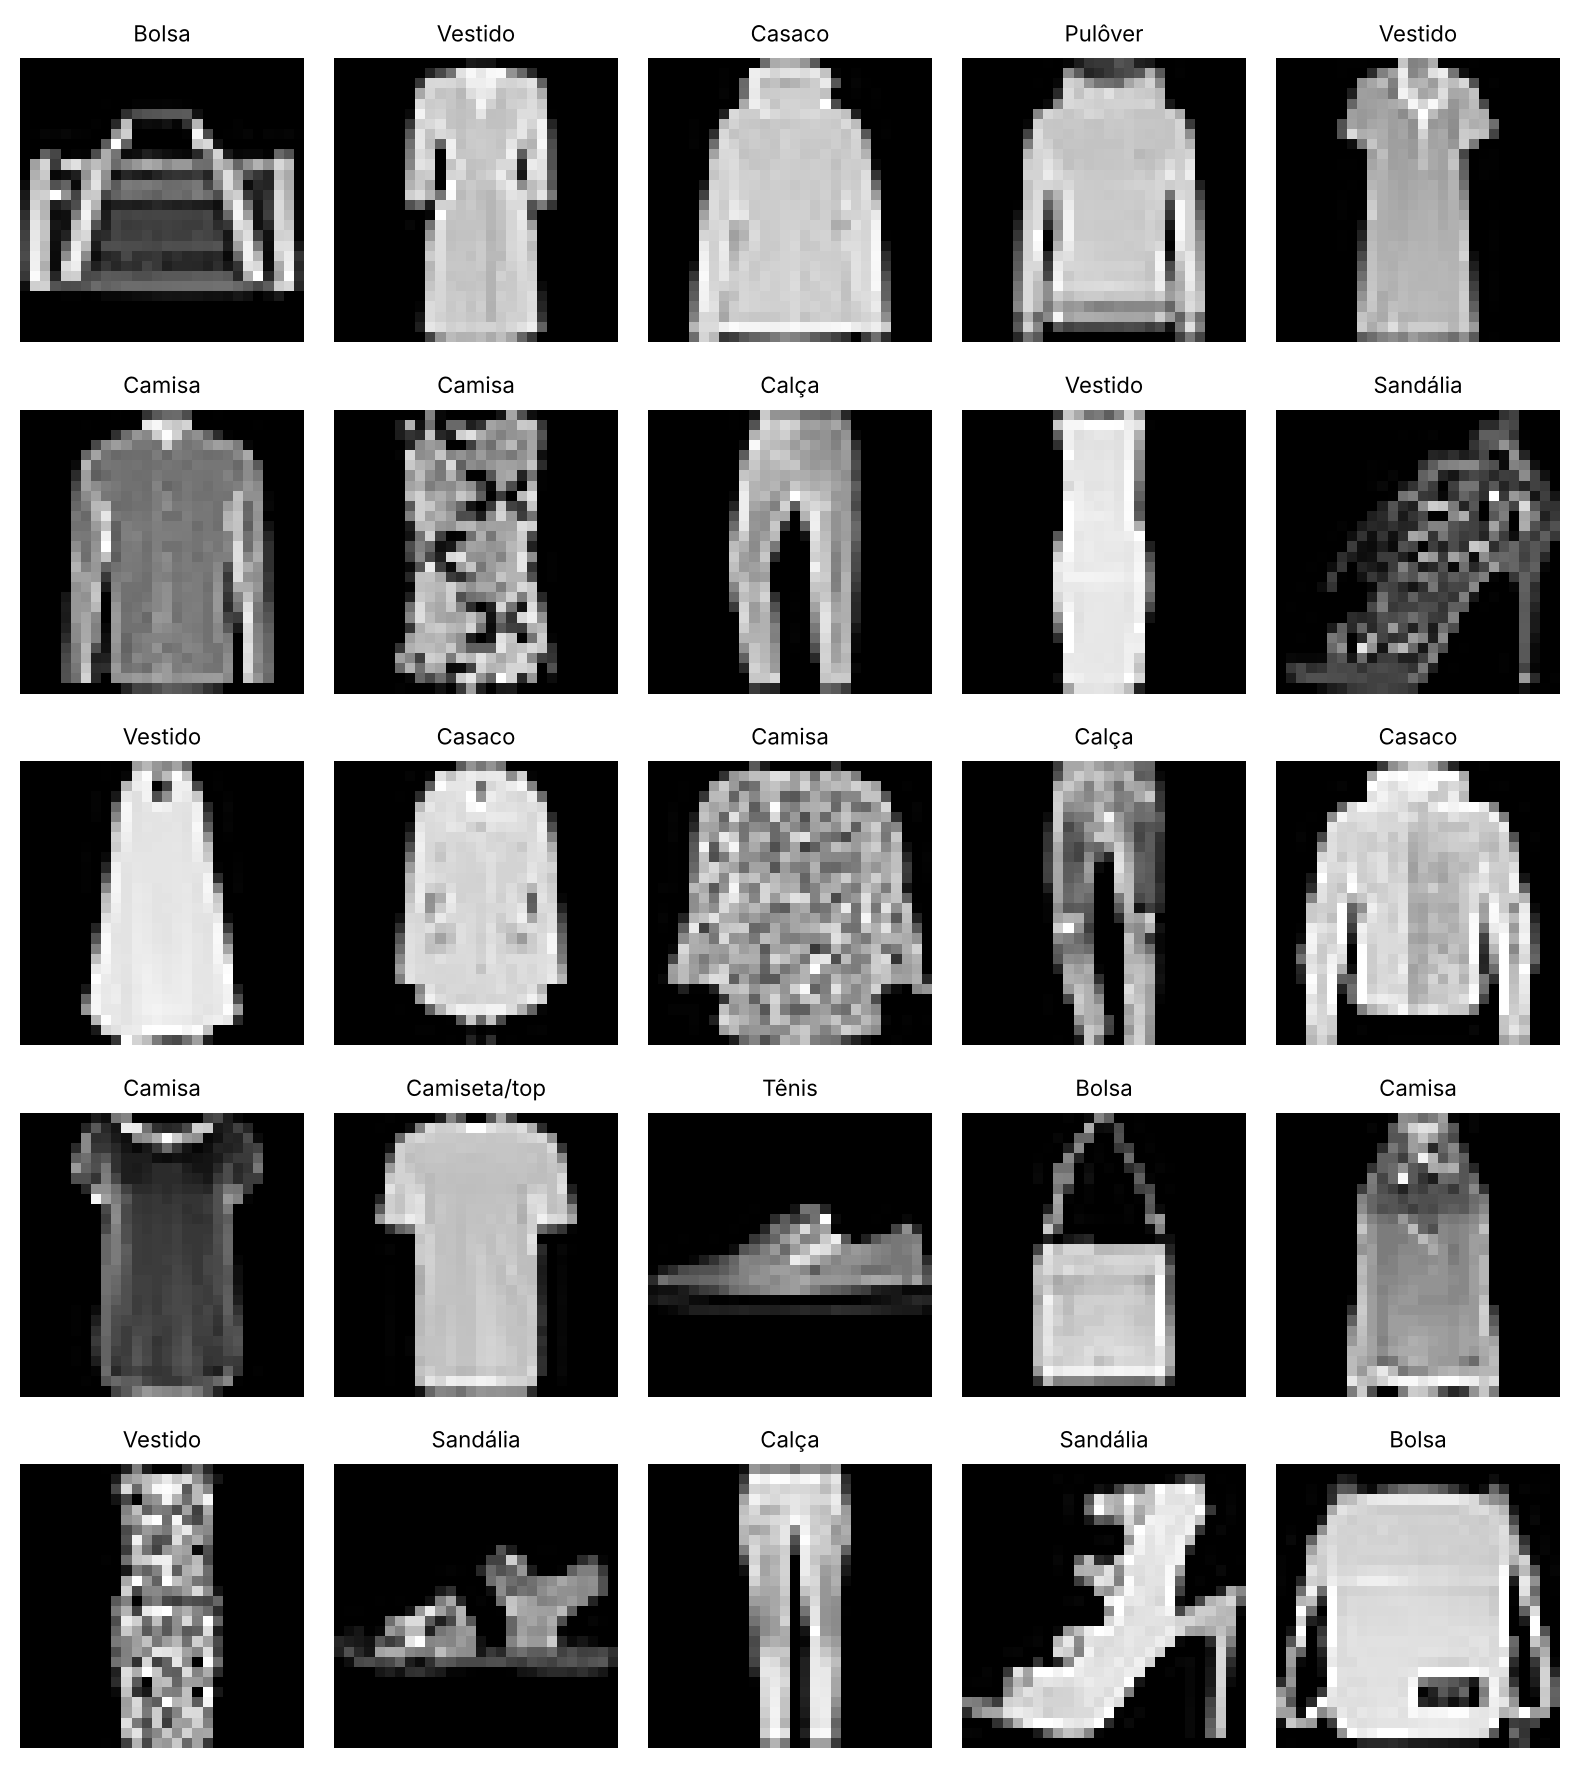

In [2]:
rng = np.random.default_rng(0)
idx = rng.choice(len(ds.X_train), 25, replace=False)
fig, axes = plt.subplots(5, 5, figsize=(8, 9))
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(ds.X_train[i].reshape(28, 28), cmap="gray")
    ax.set_title(CLASS_NAMES[ds.y_train[i]], fontsize=8)
    ax.axis("off")
plt.tight_layout()

## 2. As classes estão balanceadas?

array([5035, 5029, 4994, 5014, 5023, 4970, 4992, 5014, 5010, 4919])

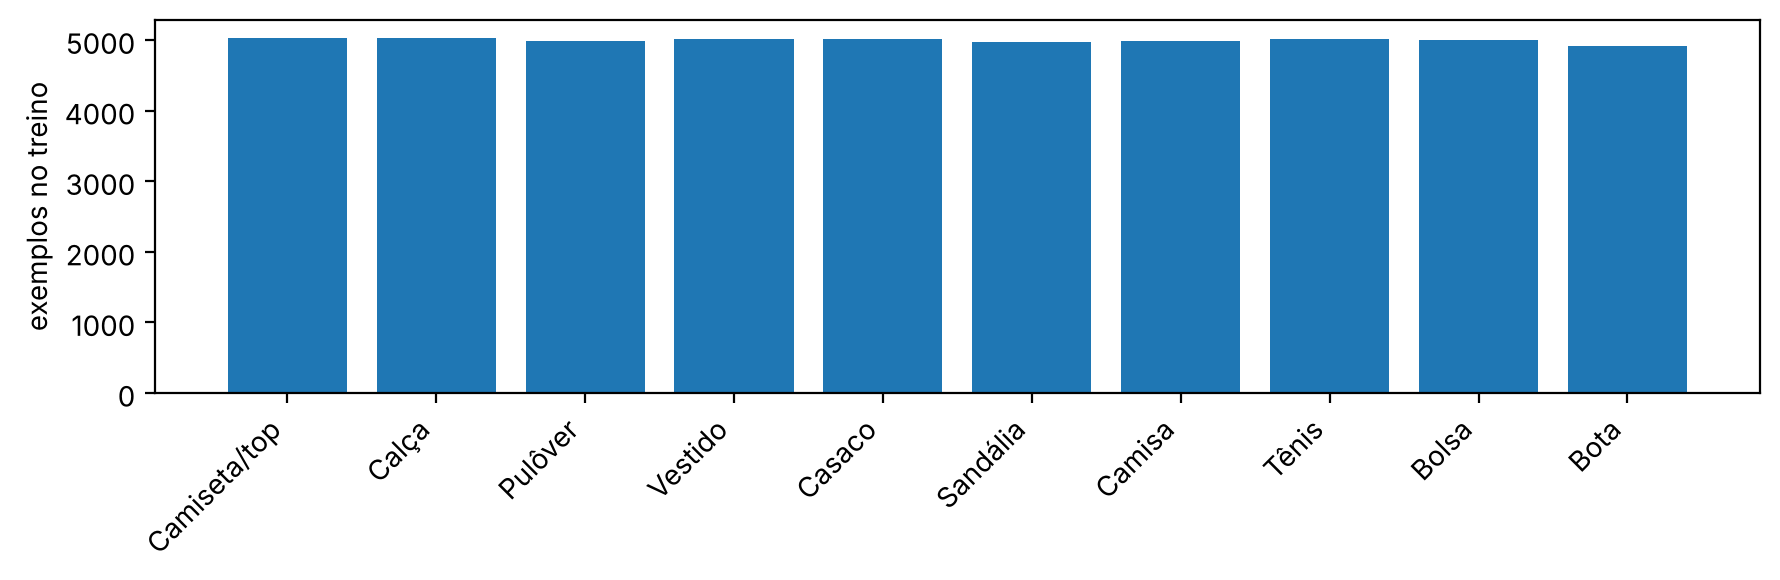

In [3]:
counts = np.bincount(ds.y_train, minlength=10)
plt.figure(figsize=(9, 3))
plt.bar(CLASS_NAMES, counts)
plt.xticks(rotation=45, ha="right")
plt.ylabel("exemplos no treino")
plt.tight_layout()
counts

## 3. Imagem média por classe

A imagem média mostra o "formato típico" de cada classe. Classes com médias parecidas tendem a ser confundidas pelo modelo.

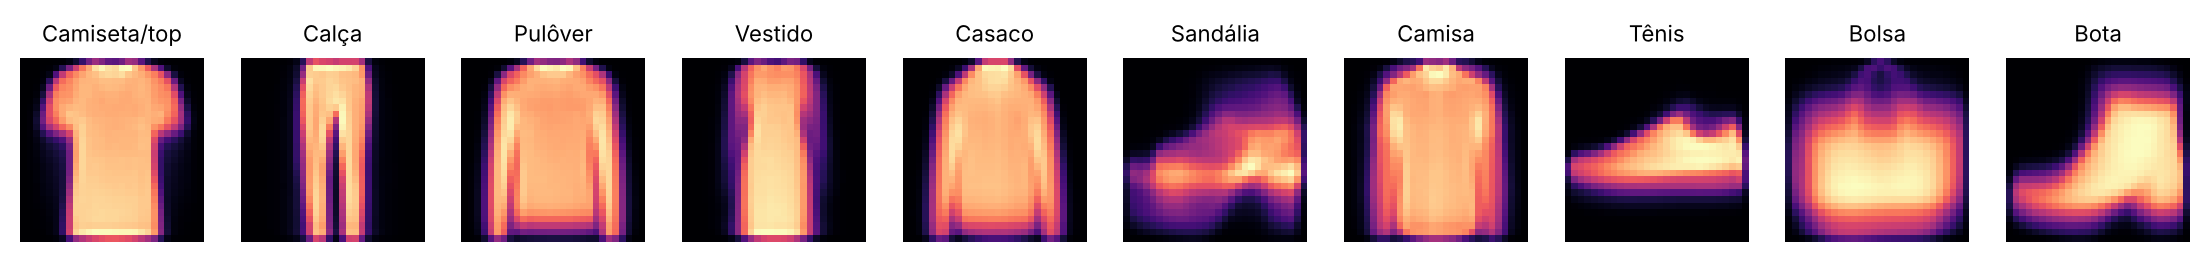

In [4]:
fig, axes = plt.subplots(1, 10, figsize=(14, 2))
for c, ax in enumerate(axes):
    ax.imshow(ds.X_train[ds.y_train == c].mean(axis=0).reshape(28, 28), cmap="magma")
    ax.set_title(CLASS_NAMES[c], fontsize=8)
    ax.axis("off")

## 4. Distribuição dos pixels

média: 0.286 | desvio: 0.353


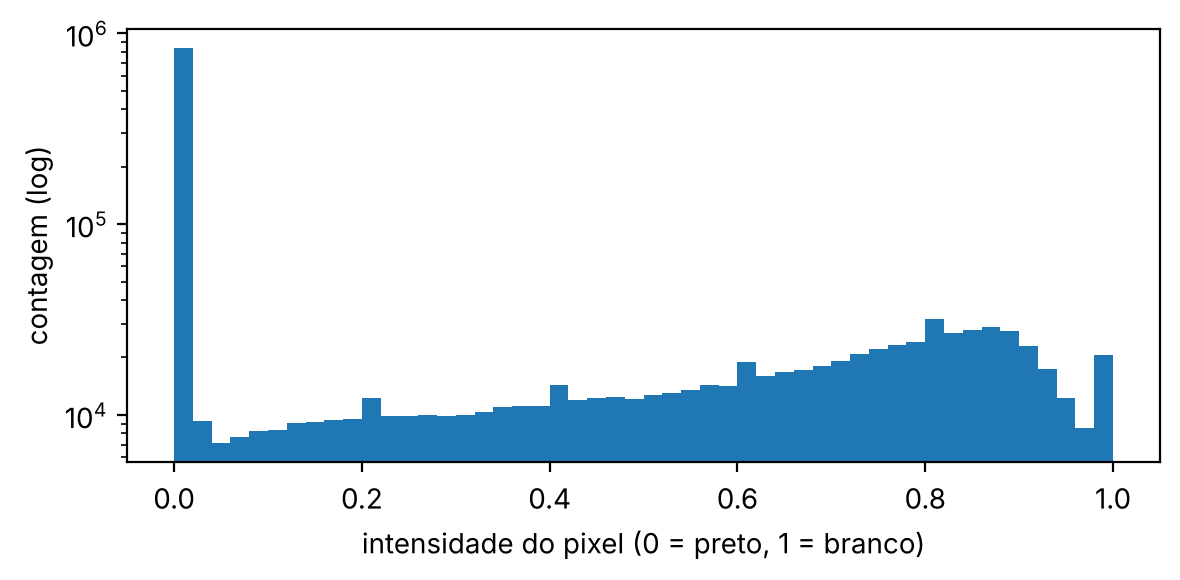

In [5]:
plt.figure(figsize=(6, 3))
plt.hist(ds.X_train[:2000].ravel(), bins=50)
plt.yscale("log")
plt.xlabel("intensidade do pixel (0 = preto, 1 = branco)")
plt.ylabel("contagem (log)")
plt.tight_layout()
print(f"média: {ds.X_train.mean():.3f} | desvio: {ds.X_train.std():.3f}")

## 5. Um classificador ingênuo como referência

Antes de qualquer rede neural: qual acurácia teríamos classificando cada imagem pela classe cuja imagem média está mais próxima? Toda rede precisa superar este número.

In [6]:
means = np.stack([ds.X_train[ds.y_train == c].mean(axis=0) for c in range(10)])
dists = ((ds.X_val[:, None, :] - means[None]) ** 2).sum(axis=2)
baseline = (dists.argmin(axis=1) == ds.y_val).mean()
print(f"acurácia do classificador por imagem média: {100 * baseline:.1f}%")

acurácia do classificador por imagem média: 68.2%


## Perguntas para responder (com suas palavras)

1. Quais pares de classes parecem mais difíceis de separar? Por quê?
2. Por que normalizamos os pixels para [0, 1]?
3. Por que a validação sai do conjunto de treino e não do de teste?
4. Qual foi a acurácia do classificador ingênuo? Que meta isso sugere para a MLP?